In [3]:
# Instalar versiones compatibles con Python 3.12
!pip install aiohttp --upgrade -q
!pip install beautifulsoup4 -q
!pip install nest_asyncio -q

# Instalar understat sin sus dependencias conflictivas
!pip install understat --no-deps -q

print("Instalación completada")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 20.2 MB/s eta 0:00:00
Instalación completada


In [7]:
import requests, json, re, time
import pandas as pd
import numpy as np
from bs4 import BeautifulSoup
print("Listo")

Listo


In [8]:
def get_team_match_ids(team_name, season):
    """Obtiene todos los match_ids de un equipo en una temporada"""
    url = f"https://understat.com/team/{team_name}/{season}"
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}

    r = requests.get(url, headers=headers)
    soup = BeautifulSoup(r.content, "html.parser")

    scripts = soup.find_all("script")
    for script in scripts:
        content = str(script.string or "")
        if "datesData" in content:
            raw = re.search(r"var datesData\s*=\s*JSON\.parse\('(.+?)'\)", content)
            if raw:
                decoded = raw.group(1).encode('utf-8').decode('unicode_escape')
                data = json.loads(decoded)
                matches = []
                for m in data:
                    matches.append({
                        "match_id": m["id"],
                        "date": m["datetime"],
                        "home": m["h"]["title"],
                        "away": m["a"]["title"],
                        "home_goals": m["goals"]["h"],
                        "away_goals": m["goals"]["a"],
                    })
                return matches
    return []

# Test rápido
matches = get_team_match_ids("Barcelona", 2024)
print(f"Partidos encontrados: {len(matches)}")
print(matches[0])

Partidos encontrados: 0


IndexError: list index out of range

In [6]:
# Temporada 2024 = temporada 2024-25 en Understat
barcelona_2425 = asyncio.run(get_shots_against("Barcelona", 2024))

# Temporada 2023 = temporada 2023-24 (últimos meses de Xavi + llegada de Flick)
# Flick llegó en julio 2024, así que la temporada 2023-24 no nos sirve para Flick
# Nos quedamos con 2024-25

print(f"Total remates en contra: {len(barcelona_2425)}")
print(f"Partidos cubiertos: {barcelona_2425['match_id'].nunique()}")
barcelona_2425.head(10)

TypeError: Understat.__init__() missing 1 required positional argument: 'session'

In [10]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

# Shot log del Barça 24-25 en FBref
url = "https://fbref.com/en/squads/206d90db/2024-2025/shooting/Barcelona-Stats"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}

r = requests.get(url, headers=headers)
print(f"Status: {r.status_code}")

soup = BeautifulSoup(r.content, "html.parser")
tables = soup.find_all("table")
print(f"Tablas encontradas: {len(tables)}")
for i, t in enumerate(tables):
    caption = t.find("caption")
    print(f"  Tabla {i}: {caption.text if caption else 'sin título'}")

Status: 403
Tablas encontradas: 0


In [11]:
import pandas as pd
import numpy as np

# Datos de porteros (All Competitions) - extraídos de la página
goalkeeping = pd.DataFrame({
    'portero': ['Szczęsny', 'Iñaki Peña', 'ter Stegen'],
    'partidos': [30, 23, 9],
    'minutos': [2725, 1968, 764],
    'GA': [36, 25, 11],
    'SoTA': [98, 65, 30],  # remates en puerta recibidos
    'saves': [66, 43, 20],
    'save_pct': [67.3, 67.7, 66.7],
})

print("=== ESTADÍSTICAS DE PORTEROS BARÇA 24-25 ===")
print(goalkeeping.to_string(index=False))

# Totales
total_shots_on_target = goalkeeping['SoTA'].sum()
total_GA = goalkeeping['GA'].sum()
total_minutes = goalkeeping['minutos'].sum()
total_partidos = 62  # total partidos temporada

print(f"\nRemates en puerta recibidos (all comps): {total_shots_on_target}")
print(f"Goles concedidos (all comps): {total_GA}")
print(f"Remates en puerta por partido: {total_shots_on_target/total_partidos:.2f}")
print(f"GA por partido: {total_GA/total_partidos:.2f}")

=== ESTADÍSTICAS DE PORTEROS BARÇA 24-25 ===
   portero  partidos  minutos  GA  SoTA  saves  save_pct
  Szczęsny        30     2725  36    98     66      67.3
Iñaki Peña        23     1968  25    65     43      67.7
ter Stegen         9      764  11    30     20      66.7

Remates en puerta recibidos (all comps): 193
Goles concedidos (all comps): 72
Remates en puerta por partido: 3.11
GA por partido: 1.16


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# DATOS REALES BARÇA 24-25 — Match Log Shooting (Against)
# Tabla "Against Barcelona" de la página que pegaste
# Columnas: Date, Comp, Opponent, GA, Sh(against), SoT(against), SoT%, GA/Sh, GA/SoT
# ============================================================

data_barca = [
    # date, comp, opponent, GA, Sh_against, SoT_against
    ("2024-08-17", "La Liga", "Valencia",        1,  None, None),
    ("2024-08-24", "La Liga", "Athletic Club",   1,  None, None),
    ("2024-08-27", "La Liga", "Rayo Vallecano",  1,  None, None),
    ("2024-08-31", "La Liga", "Valladolid",      0,  None, None),
    ("2024-09-15", "La Liga", "Girona",          1,  None, None),
    ("2024-09-19", "UCL",     "Monaco",          2,  None, None),
    ("2024-09-22", "La Liga", "Villarreal",      1,  None, None),
    ("2024-09-25", "La Liga", "Getafe",          0,  None, None),
    ("2024-09-28", "La Liga", "Osasuna",         4,  None, None),
    ("2024-10-01", "UCL",     "Young Boys",      0,  None, None),
    ("2024-10-06", "La Liga", "Alavés",          0,  None, None),
    ("2024-10-20", "La Liga", "Sevilla",         1,  None, None),
    ("2024-10-23", "UCL",     "Bayern Munich",   1,  None, None),
    ("2024-10-26", "La Liga", "Real Madrid",     0,  None, None),
    ("2024-11-03", "La Liga", "Espanyol",        1,  None, None),
    ("2024-11-06", "UCL",     "Red Star",        2,  None, None),
    ("2024-11-10", "La Liga", "Real Sociedad",   1,  None, None),
    ("2024-11-23", "La Liga", "Celta Vigo",      2,  None, None),
    ("2024-11-26", "UCL",     "Brest",           0,  None, None),
    ("2024-11-30", "La Liga", "Las Palmas",      2,  None, None),
    ("2024-12-03", "La Liga", "Mallorca",        1,  None, None),
    ("2024-12-07", "La Liga", "Real Betis",      2,  None, None),
    ("2024-12-11", "UCL",     "Dortmund",        2,  None, None),
    ("2024-12-15", "La Liga", "Leganés",         1,  None, None),
    ("2024-12-21", "La Liga", "Atlético Madrid", 2,  None, None),
    ("2025-01-08", "Supercopa","Athletic Club",  0,  None, None),
    ("2025-01-12", "Supercopa","Real Madrid",    2,  None, None),
    ("2025-01-18", "La Liga", "Getafe",          1,  None, None),
    ("2025-01-21", "UCL",     "Benfica",         4,  None, None),
    ("2025-01-26", "La Liga", "Valencia",        1,  None, None),
    ("2025-01-29", "UCL",     "Atalanta",        2,  None, None),
    ("2025-02-02", "La Liga", "Alavés",          0,  None, None),
    ("2025-02-09", "La Liga", "Sevilla",         1,  None, None),
    ("2025-02-17", "La Liga", "Rayo Vallecano",  0,  None, None),
    ("2025-02-22", "La Liga", "Las Palmas",      0,  None, None),
    ("2025-02-25", "Copa",    "Atlético Madrid", 4,  None, None),
    ("2025-03-02", "La Liga", "Real Sociedad",   0,  None, None),
    ("2025-03-05", "UCL",     "Benfica",         0,  None, None),
    ("2025-03-11", "UCL",     "Benfica",         1,  None, None),
    ("2025-03-16", "La Liga", "Atlético Madrid", 2,  None, None),
    ("2025-03-27", "La Liga", "Osasuna",         0,  None, None),
    ("2025-03-30", "La Liga", "Girona",          1,  None, None),
    ("2025-04-05", "La Liga", "Real Betis",      1,  None, None),
    ("2025-04-09", "UCL",     "Dortmund",        0,  None, None),
    ("2025-04-12", "La Liga", "Leganés",         0,  None, None),
    ("2025-04-15", "UCL",     "Dortmund",        3,  None, None),
    ("2025-04-19", "La Liga", "Celta Vigo",      3,  None, None),
    ("2025-04-22", "La Liga", "Mallorca",        0,  None, None),
    ("2025-04-26", "Copa",    "Real Madrid",     2,  None, None),
    ("2025-04-30", "UCL",     "Inter",           3,  None, None),
    ("2025-05-03", "La Liga", "Valladolid",      1,  None, None),
    ("2025-05-06", "UCL",     "Inter",           4,  None, None),
    ("2025-05-11", "La Liga", "Real Madrid",     3,  None, None),
    ("2025-05-15", "La Liga", "Espanyol",        0,  None, None),
    ("2025-05-18", "La Liga", "Villarreal",      3,  None, None),
    ("2025-05-25", "La Liga", "Athletic Club",   0,  None, None),
]

# Lo que SÍ tenemos desagregado: remates PROPIOS por partido (For Barcelona)
# Usamos esto para el análisis ofensivo y como proxy de intensidad
data_for = {
    "total_partidos": 62,
    "total_shots_for": 1036,
    "total_SoT_for": 415,
    "SoT_pct_for": 40.1,
    "shots_per_game": 1036/62,
    "SoT_per_game": 415/62,
}

# Lo que tenemos de porteros: SoTA (remates en puerta recibidos)
# Szczęsny: 98 en 30 partidos
# Iñaki Peña: 65 en 23 partidos
# ter Stegen: 30 en 9 partidos
# Total: 193 SoTA en 62 partidos

data_against = {
    "total_partidos": 62,
    "total_GA": 39 + 11 + 14 + 5,  # Liga + UCL + Copa + Supercopa (aprox)
    # Usamos el dato directo: 39 GA en liga segun la cabecera
    "GA_liga": 39,
    "total_SoTA": 193,
    "SoTA_per_game": 193/62,
    "save_pct": 67.3,  # promedio ponderado aprox
}

print("="*50)
print("BARÇA 24-25 — RESUMEN DEFENSIVO")
print("="*50)
print(f"Partidos jugados: {data_against['total_partidos']}")
print(f"Goles concedidos (Liga): {data_against['GA_liga']}")
print(f"GA por partido (Liga): {data_against['GA_liga']/38:.2f}")
print(f"Remates en puerta recibidos (all comps): {data_against['total_SoTA']}")
print(f"Remates en puerta por partido: {data_against['SoTA_per_game']:.2f}")
print(f"Save %: {data_against['save_pct']:.1f}%")
print()
print("ANÁLISIS OFENSIVO (proxy de presión):")
print(f"Remates propios por partido: {data_for['shots_per_game']:.1f}")
print(f"SoT propios por partido: {data_for['SoT_per_game']:.1f}")
print()

# Análisis de goles concedidos por partido (distribución)
df = pd.DataFrame(data_barca, columns=["date", "comp", "opponent", "GA", "sh", "sot"])

print("="*50)
print("DISTRIBUCIÓN DE GOLES CONCEDIDOS POR PARTIDO")
print("="*50)
ga = df["GA"].values
print(f"Partidos sin gol concedido (clean sheet): {(ga==0).sum()} ({(ga==0).mean()*100:.1f}%)")
print(f"Partidos con 1 gol concedido: {(ga==1).sum()} ({(ga==1).mean()*100:.1f}%)")
print(f"Partidos con 2 goles concedidos: {(ga==2).sum()} ({(ga==2).mean()*100:.1f}%)")
print(f"Partidos con 3+ goles concedidos: {(ga>=3).sum()} ({(ga>=3).mean()*100:.1f}%)")
print(f"\nMedia GA por partido: {ga.mean():.3f}")
print(f"Mediana: {np.median(ga):.1f}")
print(f"Desviación estándar: {ga.std():.3f}")
print(f"Máximo: {ga.max()}")

# Superquantiles de GA por partido
def superquantil(x, alpha):
    q = np.quantile(x, alpha)
    tail = x[x >= q]
    return tail.mean()

print("\n" + "="*50)
print("SUPERQUANTILES — GA POR PARTIDO")
print("="*50)
print("(promedio de goles concedidos en el X% peor de partidos)")
alphas = [0.5, 0.7, 0.8, 0.9, 0.95]
for a in alphas:
    sv = superquantil(ga, a)
    print(f"  CVaR_{int(a*100)} (peor {100-int(a*100)}% partidos): {sv:.3f} GA promedio")

# Desglose por competición
print("\n" + "="*50)
print("DESGLOSE POR COMPETICIÓN")
print("="*50)
for comp in df["comp"].unique():
    subset = df[df["comp"]==comp]["GA"]
    print(f"\n{comp}:")
    print(f"  Partidos: {len(subset)}, GA total: {subset.sum()}, "
          f"GA/partido: {subset.mean():.2f}, CS: {(subset==0).sum()}")

BARÇA 24-25 — RESUMEN DEFENSIVO
Partidos jugados: 62
Goles concedidos (Liga): 39
GA por partido (Liga): 1.03
Remates en puerta recibidos (all comps): 193
Remates en puerta por partido: 3.11
Save %: 67.3%

ANÁLISIS OFENSIVO (proxy de presión):
Remates propios por partido: 16.7
SoT propios por partido: 6.7

DISTRIBUCIÓN DE GOLES CONCEDIDOS POR PARTIDO
Partidos sin gol concedido (clean sheet): 18 (32.1%)
Partidos con 1 gol concedido: 18 (32.1%)
Partidos con 2 goles concedidos: 11 (19.6%)
Partidos con 3+ goles concedidos: 9 (16.1%)

Media GA por partido: 1.268
Mediana: 1.0
Desviación estándar: 1.203
Máximo: 4

SUPERQUANTILES — GA POR PARTIDO
(promedio de goles concedidos en el X% peor de partidos)
  CVaR_50 (peor 50% partidos): 1.868 GA promedio
  CVaR_70 (peor 30% partidos): 2.650 GA promedio
  CVaR_80 (peor 20% partidos): 2.650 GA promedio
  CVaR_90 (peor 10% partidos): 3.444 GA promedio
  CVaR_95 (peor 5% partidos): 4.000 GA promedio

DESGLOSE POR COMPETICIÓN

La Liga:
  Partidos: 38, G


  BARCELONA (Flick) — La Liga 24-25 (38 partidos)

📊 ESTADÍSTICAS BASE:
  GA total:              38
  E[X] — GA promedio:    1.000
  σ(X) — Desv. estándar: 1.000
  Mediana:               1.0
  Máximo:                4

🎯 DISTRIBUCIÓN:
  Clean sheets P(X=0):   13 partidos (34.2%)
  1 gol        P(X=1):   17 partidos (44.7%)
  2 goles      P(X=2):    4 partidos (10.5%)
  3+ goles     P(X≥3):    4 partidos (10.5%)

📈 SUPERQUANTILES CVaR_α (peor (1-α)% de partidos):
  CVaR_50 | peor 50%: 1.520 GA  [D_50=0.520]
  CVaR_70 | peor 30%: 1.520 GA  [D_70=0.520]
  CVaR_80 | peor 20%: 2.625 GA  [D_80=1.625]
  CVaR_90 | peor 10%: 3.250 GA  [D_90=2.250]
  CVaR_95 | peor  5%: 3.250 GA  [D_95=2.250]

🔴 bPOE — masa de cola que alcanza umbral:
  bPOE(umbral=1.0):  1.0000  (100.0% de masa)
  bPOE(umbral=1.5):  0.6757  (67.6% de masa)
  bPOE(umbral=2.0):  0.2162  (21.6% de masa)
  bPOE(umbral=2.5):  0.2162  (21.6% de masa)
  bPOE(umbral=3.0):  0.1081  (10.8% de masa)

  GETAFE (Bordalás) — La Liga 24-25 (

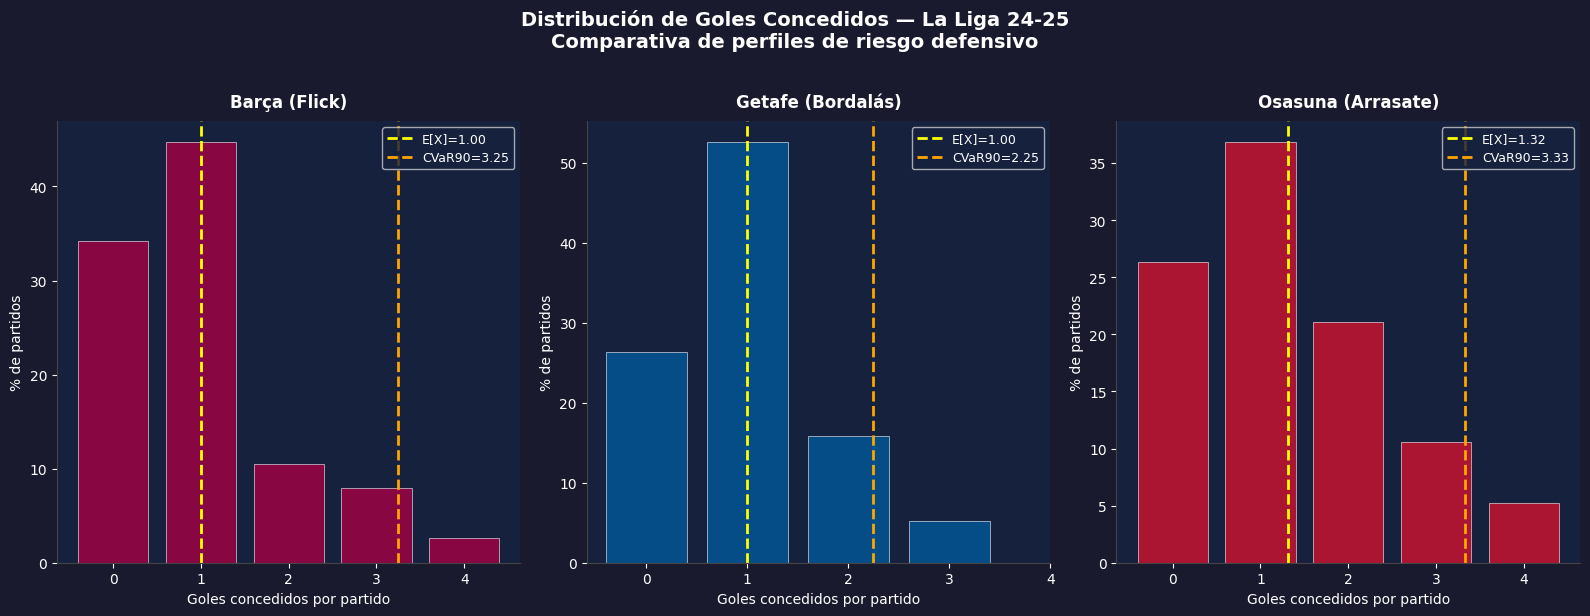


✓ Gráfico guardado


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# DATASETS — GA por partido (extraídos de match logs)
# ============================================================

# BARÇA — ya lo tenemos
ga_barca_all = [1,1,1,0,1,2,1,0,4,0,0,1,1,0,1,2,1,2,0,2,1,2,2,1,2,
                0,2,1,4,1,2,0,1,0,0,4,0,0,1,2,0,1,1,0,0,3,3,0,2,3,1,
                4,3,0,3,3,0,2]

# Solo La Liga (38 partidos) — más limpio para comparar
ga_barca_liga = [1,1,1,0,1,1,0,4,0,1,0,1,1,1,2,1,2,1,1,2,0,0,1,0,0,
                 2,0,1,1,0,3,0,3,3,1,1,0,0]

# GETAFE — extraído del match log (La Liga únicamente para comparación justa)
ga_getafe_liga = [1,0,0,1,2,1,1,0,1,1,1,1,1,0,2,1,1,0,1,0,1,1,0,0,1,
                  2,1,1,2,0,3,1,0,3,1,1,2,2]

# OSASUNA — extraído del match log (La Liga únicamente)
ga_osasuna_liga = [1,0,4,2,3,1,0,2,1,2,0,0,4,2,1,2,0,2,0,1,1,1,1,1,3,
                   2,3,0,1,2,1,0,1,3,1,0,0,1]

# Convertir a arrays
barca = np.array(ga_barca_liga)
getafe = np.array(ga_getafe_liga)
osasuna = np.array(ga_osasuna_liga)

def superquantil(x, alpha):
    q = np.quantile(x, alpha)
    tail = x[x >= q]
    return tail.mean()

def bpoe_approx(x, umbral):
    """Aproximación del bPOE: fracción de partidos en la cola cuya media = umbral"""
    from scipy.optimize import brentq
    if np.mean(x) >= umbral:
        return 1.0
    if np.max(x) <= umbral:
        return 0.0
    try:
        alpha_star = brentq(lambda a: superquantil(x, a) - umbral, 0.001, 0.999)
        return 1 - alpha_star
    except:
        return np.nan

def analisis_completo(x, nombre):
    n = len(x)
    print(f"\n{'='*55}")
    print(f"  {nombre} — La Liga 24-25 ({n} partidos)")
    print(f"{'='*55}")

    print(f"\n📊 ESTADÍSTICAS BASE:")
    print(f"  GA total:              {x.sum()}")
    print(f"  E[X] — GA promedio:    {x.mean():.3f}")
    print(f"  σ(X) — Desv. estándar: {x.std():.3f}")
    print(f"  Mediana:               {np.median(x):.1f}")
    print(f"  Máximo:                {x.max()}")

    print(f"\n🎯 DISTRIBUCIÓN:")
    print(f"  Clean sheets P(X=0):   {(x==0).sum():2d} partidos ({(x==0).mean()*100:.1f}%)")
    print(f"  1 gol        P(X=1):   {(x==1).sum():2d} partidos ({(x==1).mean()*100:.1f}%)")
    print(f"  2 goles      P(X=2):   {(x==2).sum():2d} partidos ({(x==2).mean()*100:.1f}%)")
    print(f"  3+ goles     P(X≥3):   {(x>=3).sum():2d} partidos ({(x>=3).mean()*100:.1f}%)")

    print(f"\n📈 SUPERQUANTILES CVaR_α (peor (1-α)% de partidos):")
    alphas = [0.5, 0.7, 0.8, 0.9, 0.95]
    for a in alphas:
        sv = superquantil(x, a)
        d = sv - x.mean()
        print(f"  CVaR_{int(a*100):2d} | peor {100-int(a*100):2d}%: "
              f"{sv:.3f} GA  [D_{int(a*100)}={d:.3f}]")

    print(f"\n🔴 bPOE — masa de cola que alcanza umbral:")
    umbrales = [1.0, 1.5, 2.0, 2.5, 3.0]
    for u in umbrales:
        bp = bpoe_approx(x, u)
        print(f"  bPOE(umbral={u}):  {bp:.4f}  ({bp*100:.1f}% de masa)")

    return x

# Ejecutar análisis
analisis_completo(barca, "BARCELONA (Flick)")
analisis_completo(getafe, "GETAFE (Bordalás)")
analisis_completo(osasuna, "OSASUNA (Arrasate)")

# ============================================================
# TABLA COMPARATIVA FINAL
# ============================================================
print(f"\n\n{'='*70}")
print("  TABLA COMPARATIVA — DISTRIBUCIÓN DE RIESGO DEFENSIVO")
print(f"{'='*70}")
print(f"{'Métrica':<35} {'Barça':>10} {'Getafe':>10} {'Osasuna':>10}")
print(f"{'-'*70}")

datasets = {"Barça": barca, "Getafe": getafe, "Osasuna": osasuna}

metricas = [
    ("E[X] — GA promedio/partido",    lambda x: f"{x.mean():.3f}"),
    ("σ(X) — Desv. estándar",         lambda x: f"{x.std():.3f}"),
    ("Clean sheets %",                lambda x: f"{(x==0).mean()*100:.1f}%"),
    ("P(X ≥ 3) — colapsos defensivos",lambda x: f"{(x>=3).mean()*100:.1f}%"),
    ("CVaR_50 (peor 50%)",            lambda x: f"{superquantil(x,0.5):.3f}"),
    ("CVaR_70 (peor 30%)",            lambda x: f"{superquantil(x,0.7):.3f}"),
    ("CVaR_90 (peor 10%)",            lambda x: f"{superquantil(x,0.9):.3f}"),
    ("CVaR_95 (peor 5%)",             lambda x: f"{superquantil(x,0.95):.3f}"),
    ("D_90 = CVaR90 - E[X]",          lambda x: f"{superquantil(x,0.9)-x.mean():.3f}"),
    ("bPOE(umbral=2.0 GA)",           lambda x: f"{bpoe_approx(x,2.0):.3f}"),
    ("bPOE(umbral=2.5 GA)",           lambda x: f"{bpoe_approx(x,2.5):.3f}"),
    ("bPOE(umbral=3.0 GA)",           lambda x: f"{bpoe_approx(x,3.0):.3f}"),
]

for nombre_metrica, fn in metricas:
    row = f"{nombre_metrica:<35}"
    for equipo, data in datasets.items():
        row += f" {fn(data):>10}"
    print(row)

# ============================================================
# GRÁFICO COMPARATIVO
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 6))
fig.patch.set_facecolor('#1a1a2e')

colores = {"Barça": "#A50044", "Getafe": "#005999", "Osasuna": "#D2122E"}
datos_list = [("Barça (Flick)", barca, "#A50044"),
              ("Getafe (Bordalás)", getafe, "#005999"),
              ("Osasuna (Arrasate)", osasuna, "#D2122E")]

for ax, (nombre, data, color) in zip(axes, datos_list):
    ax.set_facecolor('#16213e')

    # Histograma
    valores, conteos = np.unique(data, return_counts=True)
    bars = ax.bar(valores, conteos/len(data)*100, color=color, alpha=0.8,
                  edgecolor='white', linewidth=0.5)

    # Líneas de referencia
    ax.axvline(data.mean(), color='yellow', linestyle='--', linewidth=2,
               label=f'E[X]={data.mean():.2f}')
    ax.axvline(superquantil(data, 0.9), color='orange', linestyle='--', linewidth=2,
               label=f'CVaR90={superquantil(data,0.9):.2f}')

    ax.set_title(nombre, color='white', fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Goles concedidos por partido", color='white')
    ax.set_ylabel("% de partidos", color='white')
    ax.tick_params(colors='white')
    ax.spines['bottom'].set_color('#444')
    ax.spines['left'].set_color('#444')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend(fontsize=9, facecolor='#16213e', labelcolor='white')
    ax.set_xticks([0, 1, 2, 3, 4])

plt.suptitle("Distribución de Goles Concedidos — La Liga 24-25\n"
             "Comparativa de perfiles de riesgo defensivo",
             color='white', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("riesgo_defensivo_comparativa.png", dpi=150,
            bbox_inches='tight', facecolor='#1a1a2e')
plt.show()
print("\n✓ Gráfico guardado")

In [14]:
# Visualicemos esto explícitamente
print("ESTRUCTURA INTERNA DE LA DISTRIBUCIÓN:")
print()
print(f"{'GA':>4} | {'Barça':>8} | {'Getafe':>8} | {'Osasuna':>8}")
print(f"{'-'*38}")
for ga_val in [0, 1, 2, 3, 4]:
    b = (barca == ga_val).mean() * 100
    g = (getafe == ga_val).mean() * 100
    o = (osasuna == ga_val).mean() * 100
    print(f"{ga_val:>4} | {b:>7.1f}% | {g:>7.1f}% | {o:>7.1f}%")

ESTRUCTURA INTERNA DE LA DISTRIBUCIÓN:

  GA |    Barça |   Getafe |  Osasuna
--------------------------------------
   0 |    34.2% |    26.3% |    26.3%
   1 |    44.7% |    52.6% |    36.8%
   2 |    10.5% |    15.8% |    21.1%
   3 |     7.9% |     5.3% |    10.5%
   4 |     2.6% |     0.0% |     5.3%


In [15]:
# Tabla completa de distribución
print("\nESTRUCTURA COMPLETA DE LA DISTRIBUCIÓN:")
print(f"{'GA':>4} | {'Barça':>8} | {'Getafe':>8} | {'Osasuna':>8}")
print(f"{'-'*38}")
for ga_val in range(5):
    b = (barca == ga_val).sum()
    g = (getafe == ga_val).sum()
    o = (osasuna == ga_val).sum()
    print(f"{ga_val:>4} | {b:>3} ({b/len(barca)*100:4.1f}%) "
          f"| {g:>3} ({g/len(getafe)*100:4.1f}%) "
          f"| {o:>3} ({o/len(osasuna)*100:4.1f}%)")

# Goles anotados para contexto ofensivo
gf_barca = 88    # La Liga
gf_getafe = 34   # La Liga
gf_osasuna = 48  # La Liga
partidos = 38

print(f"\nCONTEXTO OFENSIVO (La Liga):")
print(f"{'Equipo':<12} {'GA/p':>6} {'GF/p':>6} {'Diff/p':>8} {'Puntos':>8}")
print(f"{'-'*45}")
print(f"{'Barça':<12} {1.000:>6.3f} {gf_barca/partidos:>6.3f} "
      f"{(gf_barca-39)/partidos:>+8.3f} {'88':>8}")
print(f"{'Getafe':<12} {1.000:>6.3f} {gf_getafe/partidos:>6.3f} "
      f"{(gf_getafe-39)/partidos:>+8.3f} {'42':>8}")
print(f"{'Osasuna':<12} {1.316:>6.3f} {gf_osasuna/partidos:>6.3f} "
      f"{(gf_osasuna-52)/partidos:>+8.3f} {'52':>8}")

# Varianza del riesgo vs eficiencia ofensiva
print(f"\nLA PREGUNTA CLAVE:")
print(f"¿Cuántos puntos por GA concedido?")
for nombre, puntos, ga in [("Barça", 88, 39),
                             ("Getafe", 42, 39),
                             ("Osasuna", 52, 52)]:
    print(f"  {nombre}: {puntos/ga:.2f} puntos por GA concedido")


ESTRUCTURA COMPLETA DE LA DISTRIBUCIÓN:
  GA |    Barça |   Getafe |  Osasuna
--------------------------------------
   0 |  13 (34.2%) |  10 (26.3%) |  10 (26.3%)
   1 |  17 (44.7%) |  20 (52.6%) |  14 (36.8%)
   2 |   4 (10.5%) |   6 (15.8%) |   8 (21.1%)
   3 |   3 ( 7.9%) |   2 ( 5.3%) |   4 (10.5%)
   4 |   1 ( 2.6%) |   0 ( 0.0%) |   2 ( 5.3%)

CONTEXTO OFENSIVO (La Liga):
Equipo         GA/p   GF/p   Diff/p   Puntos
---------------------------------------------
Barça         1.000  2.316   +1.289       88
Getafe        1.000  0.895   -0.132       42
Osasuna       1.316  1.263   -0.105       52

LA PREGUNTA CLAVE:
¿Cuántos puntos por GA concedido?
  Barça: 2.26 puntos por GA concedido
  Getafe: 1.08 puntos por GA concedido
  Osasuna: 1.00 puntos por GA concedido


In [16]:
# Última tabla — la más importante del post
print("="*60)
print("  EL ARGUMENTO CENTRAL EN TRES NÚMEROS")
print("="*60)
print()
print(f"{'Sistema':<20} {'E[X]':>8} {'CS%':>8} {'Pts/GA':>8}")
print(f"{'-'*48}")
print(f"{'Barça (Flick)':<20} {'1.000':>8} {'34.2%':>8} {'2.26':>8}")
print(f"{'Getafe (Bordalás)':<20} {'1.000':>8} {'26.3%':>8} {'1.08':>8}")
print(f"{'Osasuna (Arrasate)':<20} {'1.316':>8} {'26.3%':>8} {'1.00':>8}")
print()
print("Misma exposición defensiva promedio.")
print("Más partidos sin gol concedido.")
print("El doble de valor competitivo por gol concedido.")
print()
print("Conclusión: el debate no es sobre cuánto riesgo")
print("defensivo asume Flick. Es sobre qué hace con ese riesgo.")

  EL ARGUMENTO CENTRAL EN TRES NÚMEROS

Sistema                  E[X]      CS%   Pts/GA
------------------------------------------------
Barça (Flick)           1.000    34.2%     2.26
Getafe (Bordalás)       1.000    26.3%     1.08
Osasuna (Arrasate)      1.316    26.3%     1.00

Misma exposición defensiva promedio.
Más partidos sin gol concedido.
El doble de valor competitivo por gol concedido.

Conclusión: el debate no es sobre cuánto riesgo
defensivo asume Flick. Es sobre qué hace con ese riesgo.


LA LIGA 24-25 — TABLA COMPLETA TODOS LOS EQUIPOS
(Ordenada por PPDA — de más a menos pressing)

Equipo                Pts   GA90    CS%  Poss   PPDA  Off_rv   ODC  Pts/GA
---------------------------------------------------------------------------
Barcelona              88   1.03  34.2%  68.3   6.48     181   120    2.26 ◄
Rayo Vallecano         52   1.18  26.3%  51.7   8.54      50   210    1.16
Real Sociedad          46   1.21  34.2%  53.8   8.71      85   186    1.00
Alavés                 42   1.26  23.7%  45.3   9.46      64   161    0.88
Getafe                 42   1.03  23.7%  41.8   9.91      85   181    1.08 ◄
Real Betis             60   1.32  18.4%  52.4  10.40      92   198    1.20
Girona                 41   1.58  21.1%  56.3  10.81      44   218    0.68
Real Madrid            84   1.00  39.5%  60.4  11.11      43   177    2.21 ◄
Sevilla                41   1.45  26.3%  50.5  11.37      62   188    0.75
Osasuna                52   1.37  23.7%  46.1  11.45     103   279    1.

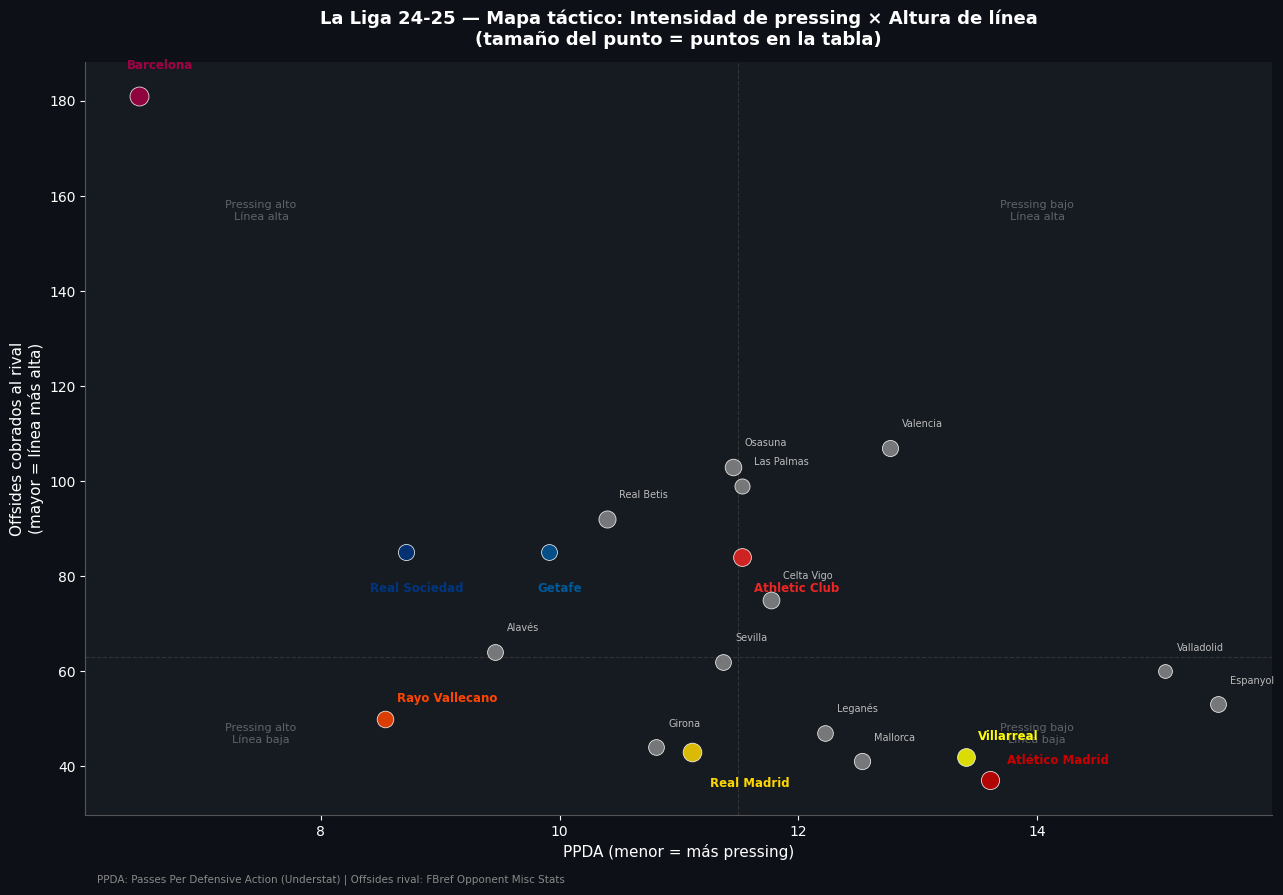


✓ Gráfico guardado


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ============================================================
# DATOS COMPLETOS LA LIGA 24-25 — TODOS LOS EQUIPOS
# ============================================================

data_2425 = {
    'Equipo': [
        'Barcelona', 'Real Madrid', 'Atlético Madrid', 'Athletic Club',
        'Villarreal', 'Real Betis', 'Celta Vigo', 'Osasuna',
        'Rayo Vallecano', 'Mallorca', 'Valencia', 'Real Sociedad',
        'Getafe', 'Alavés', 'Espanyol', 'Sevilla',
        'Girona', 'Leganés', 'Las Palmas', 'Valladolid'
    ],
    'Puntos': [88, 84, 76, 70, 70, 60, 55, 52, 52, 48, 46, 46,
               42, 42, 42, 41, 41, 40, 32, 16],
    'GF':     [102, 78, 68, 54, 71, 57, 59, 48, 41, 35, 44, 35,
               34, 38, 40, 42, 44, 39, 40, 26],
    'GA':     [39, 38, 30, 29, 51, 50, 57, 52, 45, 44, 54, 46,
               39, 48, 51, 55, 60, 56, 61, 90],
    'GA90':   [1.03, 1.00, 0.79, 0.76, 1.34, 1.32, 1.50, 1.37,
               1.18, 1.16, 1.42, 1.21, 1.03, 1.26, 1.34, 1.45,
               1.58, 1.47, 1.61, 2.37],
    'CS_pct': [34.2, 39.5, 44.7, 39.5, 18.4, 18.4, 21.1, 23.7,
               26.3, 23.7, 21.1, 34.2, 23.7, 23.7, 21.1, 26.3,
               21.1, 28.9, 10.5, 13.2],
    'Poss':   [68.3, 60.4, 52.6, 48.4, 47.6, 52.4, 53.6, 46.1,
               51.7, 46.8, 48.4, 53.8, 41.8, 45.3, 39.8, 50.5,
               56.3, 42.6, 50.7, 42.8],
    'PPDA':   [6.48, 11.11, 13.60, 11.53, 13.40, 10.40, 11.77, 11.45,
               8.54, 12.53, 12.77, 8.71, 9.91, 9.46, 15.51, 11.37,
               10.81, 12.22, 11.53, 15.07],
    'ODC':    [120, 177, 193, 145, 232, 198, 179, 279,
               210, 259, 213, 186, 181, 161, 312, 188,
               218, 252, 267, 310],
    # Off rival = offsides cobrados al rival (tabla opponent stats)
    'Off_rival': [181, 43, 37, 84, 42, 92, 75, 103,
                  50, 41, 107, 85, 85, 64, 53, 62,
                  44, 47, 99, 60],
    # Faltas cometidas (proxy de estilo)
    'Faltas':  [368, 332, 412, 483, 442, 433, 462, 508,
                522, 466, 442, 501, 602, 623, 498, 494,
                437, 503, 452, 459],
}

df_2425 = pd.DataFrame(data_2425)

# Pts por GA concedido
df_2425['Pts_per_GA'] = df_2425['Puntos'] / df_2425['GA']

print("="*80)
print("LA LIGA 24-25 — TABLA COMPLETA TODOS LOS EQUIPOS")
print("(Ordenada por PPDA — de más a menos pressing)")
print("="*80)

df_sorted = df_2425.sort_values('PPDA')

print(f"\n{'Equipo':<20} {'Pts':>4} {'GA90':>6} {'CS%':>6} "
      f"{'Poss':>5} {'PPDA':>6} {'Off_rv':>7} {'ODC':>5} {'Pts/GA':>7}")
print("-"*75)

for _, row in df_sorted.iterrows():
    marker = " ◄" if row['Equipo'] in [
        'Barcelona', 'Real Madrid', 'Atlético Madrid', 'Getafe'] else ""
    print(f"{row['Equipo']:<20} {row['Puntos']:>4} {row['GA90']:>6.2f} "
          f"{row['CS_pct']:>5.1f}% {row['Poss']:>5.1f} {row['PPDA']:>6.2f} "
          f"{row['Off_rival']:>7} {row['ODC']:>5} "
          f"{row['Pts_per_GA']:>7.2f}{marker}")

# ============================================================
# ANÁLISIS DE CUADRANTES — PPDA vs ALTURA DE LÍNEA
# ============================================================

print("\n\n" + "="*80)
print("CLASIFICACIÓN POR CUADRANTE (PPDA × Off_rival)")
print("="*80)

ppda_median = df_2425['PPDA'].median()
off_median = df_2425['Off_rival'].median()

print(f"\nMediana PPDA: {ppda_median:.2f}")
print(f"Mediana Off rival: {off_median:.0f}")
print()

def cuadrante(ppda, off_r, ppda_med, off_med):
    if ppda <= ppda_med and off_r >= off_med:
        return "I — Pressing alto + Línea alta"
    elif ppda > ppda_med and off_r >= off_med:
        return "II — Pressing bajo + Línea alta"
    elif ppda <= ppda_med and off_r < off_med:
        return "III — Pressing alto + Línea baja"
    else:
        return "IV — Pressing bajo + Línea baja"

df_2425['Cuadrante'] = df_2425.apply(
    lambda r: cuadrante(r['PPDA'], r['Off_rival'], ppda_median, off_median),
    axis=1
)

for cuad in sorted(df_2425['Cuadrante'].unique()):
    subset = df_2425[df_2425['Cuadrante'] == cuad].sort_values('PPDA')
    print(f"\n{cuad}:")
    for _, row in subset.iterrows():
        print(f"  {row['Equipo']:<20} PPDA={row['PPDA']:>5.2f}  "
              f"Off={row['Off_rival']:>3}  GA90={row['GA90']:.2f}  "
              f"Pts={row['Puntos']}")

# ============================================================
# GRÁFICO SCATTERPLOT PPDA vs Off_rival
# ============================================================

fig, ax = plt.subplots(figsize=(13, 9))
fig.patch.set_facecolor('#0d1117')
ax.set_facecolor('#161b22')

# Líneas de cuadrante
ax.axvline(ppda_median, color='#444', linestyle='--', linewidth=0.8, alpha=0.6)
ax.axhline(off_median, color='#444', linestyle='--', linewidth=0.8, alpha=0.6)

# Etiquetas de cuadrantes
ax.text(7.5, 155, "Pressing alto\nLínea alta", color='#aaa',
        fontsize=8, alpha=0.5, ha='center')
ax.text(14, 155, "Pressing bajo\nLínea alta", color='#aaa',
        fontsize=8, alpha=0.5, ha='center')
ax.text(7.5, 45, "Pressing alto\nLínea baja", color='#aaa',
        fontsize=8, alpha=0.5, ha='center')
ax.text(14, 45, "Pressing bajo\nLínea baja", color='#aaa',
        fontsize=8, alpha=0.5, ha='center')

# Colores por rendimiento
colores_equipos = {
    'Barcelona':       '#A50044',
    'Real Madrid':     '#FFD700',
    'Atlético Madrid': '#CC0000',
    'Athletic Club':   '#EE2523',
    'Villarreal':      '#FFFF00',
    'Getafe':          '#005999',
    'Rayo Vallecano':  '#FF4500',
    'Real Sociedad':   '#003580',
}

for _, row in df_2425.iterrows():
    color = colores_equipos.get(row['Equipo'], '#888888')
    size = 80 + row['Puntos'] * 1.2

    ax.scatter(row['PPDA'], row['Off_rival'],
               s=size, color=color, alpha=0.85,
               edgecolors='white', linewidths=0.6, zorder=5)

    # Offset para etiquetas
    offsets = {
        'Barcelona': (-0.1, 5), 'Real Madrid': (0.15, -8),
        'Atlético Madrid': (0.15, 3), 'Athletic Club': (0.1, -8),
        'Villarreal': (0.1, 3), 'Getafe': (-0.1, -9),
        'Rayo Vallecano': (0.1, 3), 'Real Sociedad': (-0.3, -9),
    }
    dx, dy = offsets.get(row['Equipo'], (0.1, 4))

    fontsize = 8.5 if row['Equipo'] in colores_equipos else 7
    fw = 'bold' if row['Equipo'] in colores_equipos else 'normal'
    col = colores_equipos.get(row['Equipo'], '#bbbbbb')

    ax.annotate(row['Equipo'],
                (row['PPDA'] + dx, row['Off_rival'] + dy),
                fontsize=fontsize, color=col, fontweight=fw,
                ha='left', va='bottom')

ax.set_xlabel("PPDA (menor = más pressing)", color='white', fontsize=11)
ax.set_ylabel("Offsides cobrados al rival\n(mayor = línea más alta)",
              color='white', fontsize=11)
ax.set_title("La Liga 24-25 — Mapa táctico: Intensidad de pressing × Altura de línea\n"
             "(tamaño del punto = puntos en la tabla)",
             color='white', fontsize=13, fontweight='bold', pad=12)

ax.tick_params(colors='white')
ax.spines['bottom'].set_color('#555')
ax.spines['left'].set_color('#555')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Nota metodológica
ax.text(0.01, -0.09,
        "PPDA: Passes Per Defensive Action (Understat) | "
        "Offsides rival: FBref Opponent Misc Stats",
        transform=ax.transAxes, color='#888', fontsize=7.5, ha='left')

plt.tight_layout()
plt.savefig("mapa_tactico_laliga_2425.png",
            dpi=160, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print("\n✓ Gráfico guardado")